# NR calculations for a supported lipid bilayer

Let us consider the expected NR curves from a system of a SLB at the Si/D$_2$O interface. We can build a simple model where the lipid bilayer is represented by a three layers head/tails/heads. 

In [1]:
from anaklasis import ref

# We give a name to the project
project='SLB_D2O_calculations'


Now let us define the model (single uniform patch) Si / SiO2 / water/ SLB / water and also the model-parameters.

In [2]:
model = [
	# Re_sld Im_sld thk rough solv description
	[  2.07e-6, 0.0, 0, 2.0, 0.0, 'Si'],
	[ 3.5e-6, 0.0, 10, 'p0', 0.0, 'SiO2'],
    [ 'p4', 0.0, 5, 'p0', 0.0, 'water layer'],
    [ 1.7e-6, 0.0, 'p1', 'p2', 0.3, 'inner heads'],
    [ -0.4e-6, 0.0, 'p3', 'p2', 0.0, 'tails'],
    [ 1.7e-6, 0.0, 'p1', 'p2', 0.3, 'outer heads'],
	[  'p4', 0.0,  0, 0.0, 1.0, 'bulk'],
	]

patches=[1.0]
system=[model]

global_param = [
    # param  min  max  description, for type 'uniform'
	['p0', 3.0, 'SiO2_roughness'],
	['p1', 9.0, 'heads_thickness'],
	['p2', 3.0, 'slb_roughness'],
	['p3', 35, 'tail_thickness'],
	['p4', 6.35e-6, 'solv_sld'],
	]



We also set the instrumental parameters

In [3]:
resolution=[0.06] # dQ/Q=6%
background = [0.5e-6] #no background
scale = [1.0]
qmax = [0.3]

Finally we call the anaklasis.fit function

--------------------------------------------------------------------
Program ANAKLASIS - Calculation Module for X-ray/Neutron reflection 
version 1.6.0, September 2021
developed by Dr. Alexandros Koutsioumpas. JCNS @ MLZ
for bugs and requests contact: a.koutsioumpas[at]fz-juelich.de
--------------------------------------------------------------------
Directory already exists.. overwriting data..


Instrumental Resolution, dQ/Q: 0.06
--------------------------------------------------------------------
Si real sld (10^-6 A^-2)      = 2.07 
Si imaginary sld (10^-6 A^-2) = 0.00 
Si thickness (A)              = 0.00 
Si/SiO2 roughness (A) = 2.00 
Si solvent volume fraction    = 0.00 
--------------------------------------------------------------------
SiO2 real sld (10^-6 A^-2)      = 3.50 
SiO2 imaginary sld (10^-6 A^-2) = 0.00 
SiO2 thickness (A)              = 10.00 
SiO2/water layer roughness (A) = 3.00 (parametric), -> p0
SiO2 solvent volume fraction    = 0.00 
------------------------

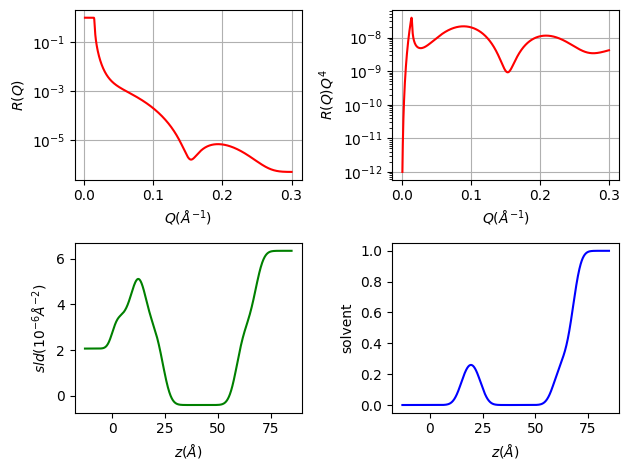

Library versions used for the calculations:
numpy: 2.2.6
scipy: 1.15.2
numdifftools: 0.9.41
sympy: 1.13.1
numba: 0.61.2


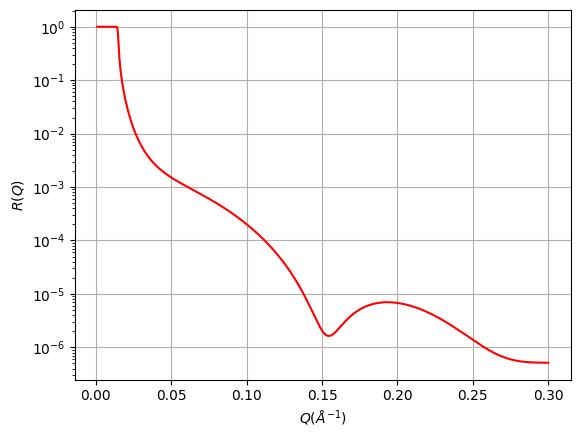

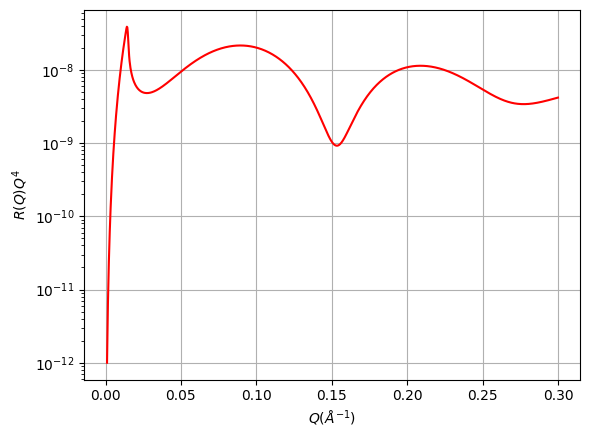

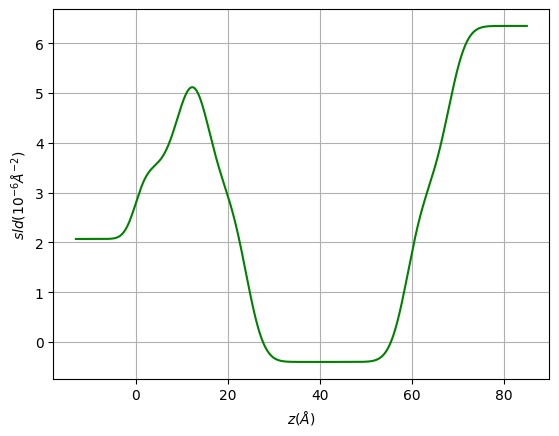

In [4]:
res = ref.calculate(project,resolution,patches,system,global_param
	,background,scale,qmax,plot=True)

As we can see from the plots, the experimental data are nicely fitted using the defined model.